# 06 Statistical quality control charts for air quality

**Tutorial item 5** (quality control charts). The question: *when does Delhi's air quality go out of statistical
control?* A control chart separates **common-cause** variation (the usual month-to-month noise of a stable process)
from **special causes** (events that need an explanation).

Charts built here:
1. **Individuals (I) and moving-range (MR) chart** of monthly mean AQI;
2. the same chart on **seasonally adjusted** AQI, because a raw I-chart on a seasonal series breaks the chart's
   core assumption (independent observations from one stable distribution);
3. **X̄ and S chart** treating each month's daily readings as a rational subgroup;
4. **p-chart** of the monthly share of Poor-or-worse days, with variable subgroup size, plus a **Laney p′ chart**
   that corrects for over-dispersion;
5. **Phase II**: 2020 months plotted against limits from 2015-2019.

**Outputs:** `outputs/control_chart.csv` and `outputs/p_chart.csv` (read by the app).

In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np, pandas as pd, matplotlib.pyplot as plt
from src.utils import *
set_plot_style()

daily = load_clean(index_by_date=True)
m = daily.resample("MS").agg(mean_AQI=("AQI", "mean"), sd_AQI=("AQI", "std"), n=("AQI", "size"),
                             poor_days=("Poor_Flag", "sum"))
m["p_poor"] = m["poor_days"] / m["n"]
print(m.shape)
m.head()

(60, 5)


,mean_AQI,sd_AQI,n,poor_days,p_poor
Date,,,,,
2015-01-01,342.290323,55.736998,31,30,0.967742
2015-02-01,327.928571,31.200580,28,28,1.000000
2015-03-01,256.064516,59.966622,31,25,0.806452
2015-04-01,305.266667,58.480727,30,30,1.000000
2015-05-01,348.580645,39.390163,31,31,1.000000


## Constants and run rules
For individuals charts sigma is estimated from the average moving range: σ̂ = MR̄ / d₂ with d₂ = 1.128 (n = 2), so
limits are centre ± 3σ̂ = centre ± 2.66·MR̄, and the MR chart's upper limit is D₄·MR̄ = 3.267·MR̄.

Points are flagged by the **Western Electric rules**:
1. one point beyond 3σ;
2. two of three consecutive points beyond 2σ on the same side;
3. four of five consecutive points beyond 1σ on the same side;
4. eight consecutive points on the same side of the centre line.

In [2]:
D2, D4 = 1.128, 3.267

def we_rules(x, centre, sigma):
    x = np.asarray(x, float); z = (x - centre) / sigma; n = len(x)
    flags = {r: np.zeros(n, bool) for r in (1, 2, 3, 4)}
    flags[1] = np.abs(z) > 3
    for i in range(n):
        for side in (1, -1):
            w3 = z[max(0, i - 2):i + 1] * side
            if len(w3) == 3 and (w3 > 2).sum() >= 2 and z[i] * side > 2: flags[2][i] = True
            w5 = z[max(0, i - 4):i + 1] * side
            if len(w5) == 5 and (w5 > 1).sum() >= 4 and z[i] * side > 1: flags[3][i] = True
            w8 = z[max(0, i - 7):i + 1] * side
            if len(w8) == 8 and (w8 > 0).all(): flags[4][i] = True
    rule = np.array(["".join(str(r) for r in (1, 2, 3, 4) if flags[r][i]) for i in range(n)])
    return rule

def i_mr(x):
    x = pd.Series(x)
    mr = x.diff().abs()
    mrbar = mr.mean()
    sigma = mrbar / D2
    centre = x.mean()
    return centre, sigma, mrbar

def plot_i_mr(x, title, fname, ylabel):
    centre, sigma, mrbar = i_mr(x)
    rules = we_rules(x, centre, sigma)
    ucl, lcl = centre + 3 * sigma, max(centre - 3 * sigma, 0)
    mr = x.diff().abs()
    fig, ax = plt.subplots(2, 1, figsize=(12, 6.5), sharex=True, gridspec_kw={"height_ratios": [2, 1]})
    ax[0].plot(x.index, x, "-o", ms=3, color="C0")
    for k, ls in ((1, ":"), (2, "--")):
        ax[0].axhline(centre + k * sigma, color="0.6", ls=ls, lw=.8); ax[0].axhline(centre - k * sigma, color="0.6", ls=ls, lw=.8)
    ax[0].axhline(centre, color="k", lw=1); ax[0].axhline(ucl, color="C3"); ax[0].axhline(lcl, color="C3")
    out = rules != ""
    ax[0].scatter(x.index[out], x[out], color="C3", s=40, zorder=5, label="signal (Western Electric rule)")
    ax[0].set(title=f"{title}: individuals chart", ylabel=ylabel)
    ax[0].text(x.index[-1], ucl, f" UCL {ucl:.0f}", va="center", fontsize=8, color="C3")
    ax[0].text(x.index[-1], centre, f" CL {centre:.0f}", va="center", fontsize=8)
    ax[0].text(x.index[-1], lcl, f" LCL {lcl:.0f}", va="center", fontsize=8, color="C3")
    ax[0].legend(fontsize=8, loc="upper left")
    ax[1].plot(mr.index, mr, "-o", ms=3, color="C2")
    ax[1].axhline(mrbar, color="k", lw=1); ax[1].axhline(D4 * mrbar, color="C3")
    ax[1].scatter(mr.index[mr > D4 * mrbar], mr[mr > D4 * mrbar], color="C3", s=40, zorder=5)
    ax[1].set(title="Moving range chart", ylabel="|change| from previous month")
    plt.tight_layout(); save_figure(fig, fname); plt.show()
    return pd.DataFrame({"value": x, "centre": centre, "ucl": ucl, "lcl": lcl, "sigma": sigma, "rule": rules,
                         "out_of_control": out.astype(int), "mr": mr, "mr_ucl": D4 * mrbar})

## 1. I-MR chart on monthly mean AQI (raw)

centre = 266.6, sigma (MR-bar/d2) = 52.5 vs ordinary SD = 98.9
limits: LCL 109.0, UCL 424.1
signalled months: 14 of 60


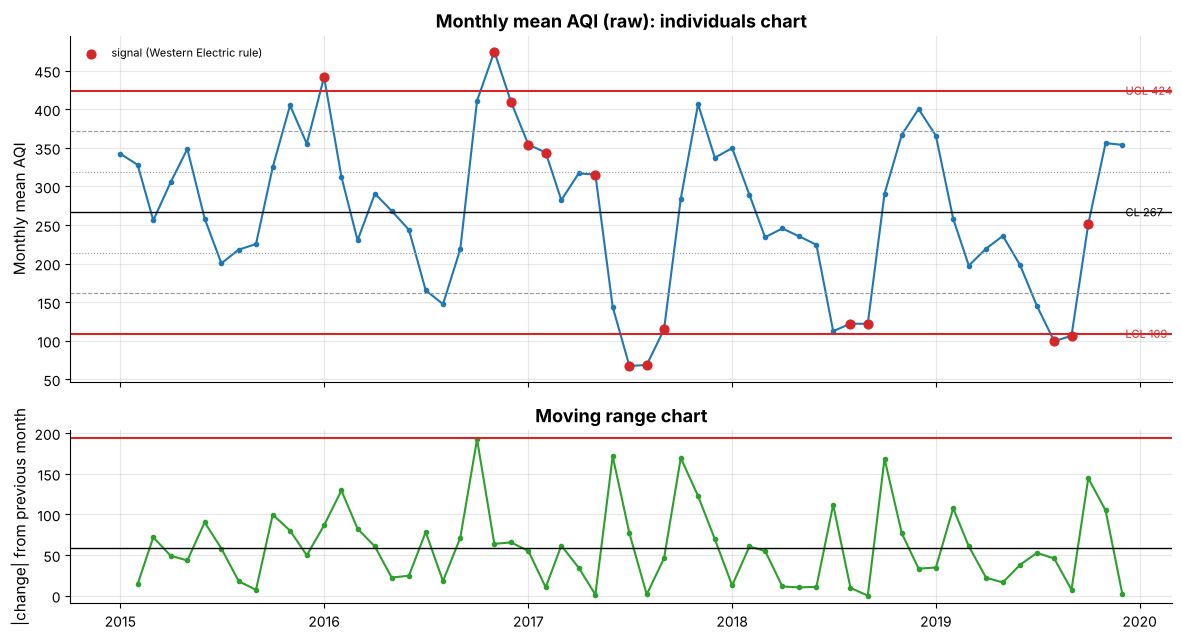

month,2016-01,2016-11,2016-12,2017-01,2017-02,2017-05,2017-07,2017-08,2017-09,2018-08,2018-09,2019-08,2019-09,2019-10
value,441.9,474.8,409.3,354.2,343.9,315.4,67.2,68.7,114.7,122.1,121.9,99.3,106.5,251.0
rule,123,12,2,3,3,4,12,12,23,2,2,12,1234,4


In [3]:
x = m["mean_AQI"]
raw_tab = plot_i_mr(x, "Monthly mean AQI (raw)", "06_imr_raw", "Monthly mean AQI")
c, s_, mrbar = i_mr(x)
print(f"centre = {c:.1f}, sigma (MR-bar/d2) = {s_:.1f} vs ordinary SD = {x.std():.1f}")
print(f"limits: LCL {max(c - 3 * s_, 0):.1f}, UCL {c + 3 * s_:.1f}")
print(f"signalled months: {raw_tab['out_of_control'].sum()} of {len(raw_tab)}")
raw_tab.loc[raw_tab["out_of_control"] == 1, ["value", "rule"]].assign(month=lambda d: d.index.strftime("%Y-%m")).set_index("month").round(1).T

**Raw I-MR chart.** Centre 266.6 with limits 109 to 424. Sigma from the moving range (52.5) is much smaller than
the ordinary standard deviation (98.9), because consecutive months are similar and the moving range ignores the
slow seasonal swing. 14 of 60 months signal. Two above the UCL are genuine special causes: **November 2016
(474.8)**, the "Great Smog" when Delhi closed schools for days after Diwali and heavy stubble burning, and January
2016 (441.9). But most signals are simply *the season*: July-September 2017-2019 below the LCL, winter runs above
the centre. A raw chart on a seasonal series confuses "it is monsoon" with "something unusual happened", so it is
not a valid monitoring tool here.

## 2. I-MR chart on seasonally adjusted AQI
Each month's value minus that calendar month's 2015-2019 average (plus the overall mean, to stay on the AQI
scale). What is left is the part of the month that the season cannot explain, which is what a control chart should
watch.

lag-1 autocorrelation: raw 0.70, seasonally adjusted 0.67
signalled months: 20 of 60


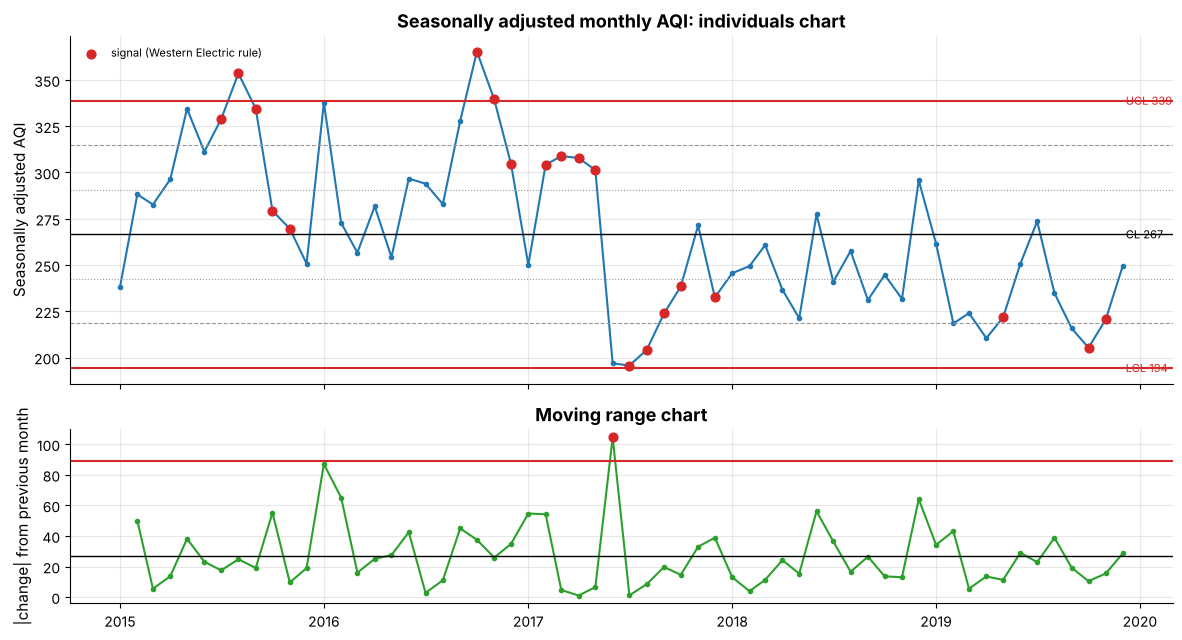

month,2015-07,2015-08,2015-09,2015-10,2015-11,2016-10,2016-11,2016-12,2017-02,2017-03,2017-04,2017-05,2017-07,2017-08,2017-09,2017-10,2017-12,2019-05,2019-10,2019-11
value,328.8,353.5,334.5,279.3,269.7,365.3,339.5,304.7,304.2,308.9,307.9,301.3,195.7,204.2,223.8,238.4,232.5,221.7,205.3,220.7
rule,23,123,234,4,4,123,123,3,3,3,3,3,2,2,3,3,3,3,2,3


In [4]:
clim = m.groupby(m.index.month)["mean_AQI"].transform("mean")
xs = m["mean_AQI"] - clim + m["mean_AQI"].mean()
adj_tab = plot_i_mr(xs, "Seasonally adjusted monthly AQI", "06_imr_adjusted", "Seasonally adjusted AQI")
r1 = pd.Series(xs).autocorr(1)
print(f"lag-1 autocorrelation: raw {x.autocorr(1):.2f}, seasonally adjusted {r1:.2f}")
print(f"signalled months: {adj_tab['out_of_control'].sum()} of {len(adj_tab)}")
adj_tab.loc[adj_tab["out_of_control"] == 1, ["value", "rule"]].assign(month=lambda d: d.index.strftime("%Y-%m")).set_index("month").round(1).T

**Seasonally adjusted I-MR chart.** With the calendar effect removed, the limits are 194 to 339 around 266.6.
Three months break the 3σ limit, all on the high side: **August 2015 (354), October 2016 (365) and November 2016
(339)**. Autumn 2016 stands out even after allowing for the season, which confirms the 2016 smog episode as a
special cause.

The other 17 signals come from the run rules (2, 3 and 4), and they tell a story of a **shift**: months in 2015-16
and early 2017 sit *above* the centre, months from mid-2017 onward *below* it. The process is not stable; its level
moved down, the same improving trend found in notebook 05 (about -19 AQI per year). A good special cause.

**Caveat.** The adjusted series is still autocorrelated (lag-1 r = 0.67). Control charts assume independence, and
with positive autocorrelation the run rules fire too often. A stricter approach charts the residuals of the
time-series model (e.g. the causal regression's residuals); the conclusion here (a 2016 episode plus a downward
shift) is robust because the rule-1 signals and the direction of the runs agree.

## 3. X̄ and S chart with each month as a rational subgroup
Subgroup sizes vary (28 to 31 days), so the limits vary slightly: X̄ limits = X̿ ± A₃·S̄, S limits B₃·S̄ and B₄·S̄,
with the constants computed from c₄(n).

X-bar: centre 266.3, typical limits ±35.4; months outside: 45 of 60
S: S-bar 64.5; months outside: 15 of 60


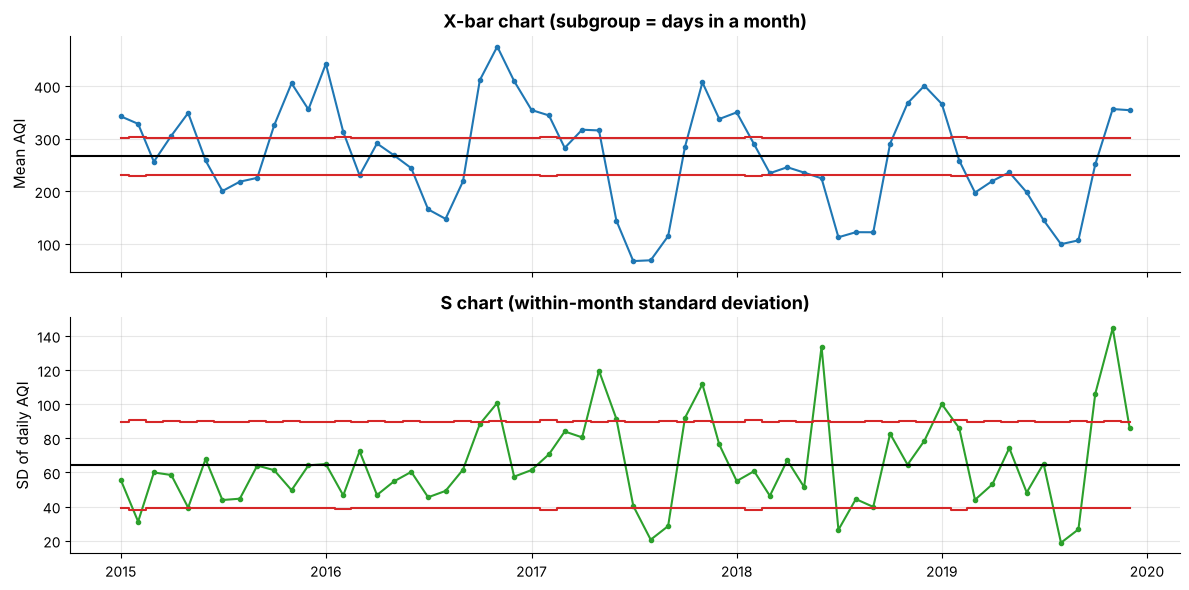

In [5]:
from scipy.special import gammaln
def c4(n): return np.sqrt(2 / (n - 1)) * np.exp(gammaln(n / 2) - gammaln((n - 1) / 2))
n_i = m["n"].values
sbar = np.average(m["sd_AQI"], weights=m["n"] - 1)
xbarbar = np.average(m["mean_AQI"], weights=m["n"])
A3 = 3 / (c4(n_i) * np.sqrt(n_i))
B3 = np.maximum(0, 1 - 3 * np.sqrt(1 - c4(n_i) ** 2) / c4(n_i))
B4 = 1 + 3 * np.sqrt(1 - c4(n_i) ** 2) / c4(n_i)
fig, ax = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
ax[0].plot(m.index, m["mean_AQI"], "-o", ms=3); ax[0].axhline(xbarbar, color="k")
ax[0].plot(m.index, xbarbar + A3 * sbar, color="C3", drawstyle="steps-mid"); ax[0].plot(m.index, xbarbar - A3 * sbar, color="C3", drawstyle="steps-mid")
ax[0].set(title="X-bar chart (subgroup = days in a month)", ylabel="Mean AQI")
ax[1].plot(m.index, m["sd_AQI"], "-o", ms=3, color="C2"); ax[1].axhline(sbar, color="k")
ax[1].plot(m.index, B4 * sbar, color="C3", drawstyle="steps-mid"); ax[1].plot(m.index, B3 * sbar, color="C3", drawstyle="steps-mid")
ax[1].set(title="S chart (within-month standard deviation)", ylabel="SD of daily AQI")
plt.tight_layout(); save_figure(fig, "06_xbar_s"); plt.show()
out_x = ((m["mean_AQI"] > xbarbar + A3 * sbar) | (m["mean_AQI"] < xbarbar - A3 * sbar)).sum()
out_s = ((m["sd_AQI"] > B4 * sbar) | (m["sd_AQI"] < B3 * sbar)).sum()
print(f"X-bar: centre {xbarbar:.1f}, typical limits ±{(A3 * sbar).mean():.1f}; months outside: {out_x} of {len(m)}")
print(f"S: S-bar {sbar:.1f}; months outside: {out_s} of {len(m)}")

**X̄ and S chart.** 45 of 60 months fall outside the X̄ limits. That is not 45 crises: the limits (about ±35) are
built from *within-month* day-to-day variation (S̄ = 64.5), but the dominant variation is *between* months (the
season). This is the textbook failure of rational subgrouping: a subgroup must contain only common-cause variation,
and a calendar month of autocorrelated days does not. The S chart (15 months outside) shows that day-to-day
volatility itself varies, and is higher in episode-prone months. Conclusion: for this process the individuals chart
on seasonally adjusted data is the right tool, not X̄-S.

## 4. p-chart of the monthly share of Poor-or-worse days
p̄ = total Poor days / total days; for month i with n_i days the limits are p̄ ± 3·sqrt(p̄(1 - p̄)/n_i), clipped to
[0, 1]. Laney's p′ chart multiplies the binomial sigma by σ_z, the moving-range sigma of the standardised values,
to allow for between-month variation that the binomial model ignores.

p-bar = 0.680; binomial limits for a 30-day month: 0.424 to 0.935
months outside binomial p-chart limits: 36 of 60
sigma_z = 1.97 (1 = binomial fits; >1 = over-dispersion) -> months outside Laney limits: 10
dispersion test: chi2 = 1014.8 on 59 df


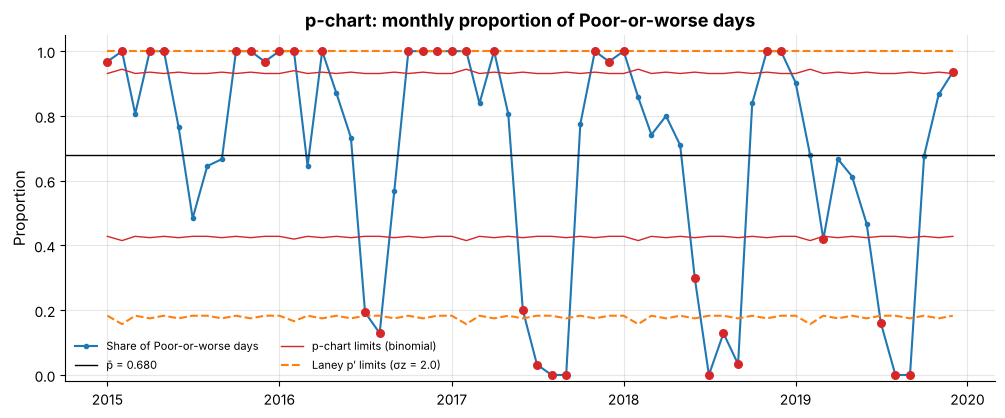

In [6]:
pbar = m["poor_days"].sum() / m["n"].sum()
sig_i = np.sqrt(pbar * (1 - pbar) / m["n"])
ucl_p = np.minimum(pbar + 3 * sig_i, 1); lcl_p = np.maximum(pbar - 3 * sig_i, 0)
z = (m["p_poor"] - pbar) / sig_i
sigma_z = z.diff().abs().mean() / D2
ucl_l = np.minimum(pbar + 3 * sig_i * sigma_z, 1); lcl_l = np.maximum(pbar - 3 * sig_i * sigma_z, 0)
p_out = (m["p_poor"] > ucl_p) | (m["p_poor"] < lcl_p)
l_out = (m["p_poor"] > ucl_l) | (m["p_poor"] < lcl_l)
fig, ax = plt.subplots(figsize=(12, 4.5))
ax.plot(m.index, m["p_poor"], "-o", ms=3, label="Share of Poor-or-worse days")
ax.axhline(pbar, color="k", lw=1, label=f"p̄ = {pbar:.3f}")
ax.plot(m.index, ucl_p, color="C3", lw=1, label="p-chart limits (binomial)")
ax.plot(m.index, lcl_p, color="C3", lw=1)
ax.plot(m.index, ucl_l, color="C1", ls="--", label=f"Laney p′ limits (σz = {sigma_z:.1f})")
ax.plot(m.index, lcl_l, color="C1", ls="--")
ax.scatter(m.index[p_out], m["p_poor"][p_out], color="C3", s=30, zorder=5)
ax.set(title="p-chart: monthly proportion of Poor-or-worse days", ylabel="Proportion", ylim=(-.02, 1.05))
ax.legend(fontsize=8, loc="lower left", ncol=2)
save_figure(fig, "06_p_chart"); plt.show()
print(f"p-bar = {pbar:.3f}; binomial limits for a 30-day month: {pbar - 3*np.sqrt(pbar*(1-pbar)/30):.3f} to {pbar + 3*np.sqrt(pbar*(1-pbar)/30):.3f}")
print(f"months outside binomial p-chart limits: {p_out.sum()} of {len(m)}")
print(f"sigma_z = {sigma_z:.2f} (1 = binomial fits; >1 = over-dispersion) -> months outside Laney limits: {l_out.sum()}")
print("dispersion test: chi2 =", round(float(((m['poor_days'] - m['n'] * pbar) ** 2 / (m['n'] * pbar * (1 - pbar))).sum()), 1),
      "on", len(m) - 1, "df")

**p-chart of Poor days.** p̄ = 0.680; for a 30-day month the binomial limits are 0.42 to 0.94. 36 of 60 months
fall outside, but the dispersion test shows why: chi² = 1,014.8 on 59 df, about 17 times its expected value. Days in
a month are not independent coin flips (a smog spell lasts a week), so the binomial model badly understates
month-to-month variation (**over-dispersion**). Laney's p′ chart widens the limits by σz = 1.97, after which 10
months remain below the lower limit: the monsoon months of 2016-2019 (July-September), when 0 to 16% of days were
Poor. No month signals on the high side, because in winter almost every day is already Poor (p is close to 1).
Monsoon months remain genuinely, systematically different, so a fully valid p-chart would need season-specific
centre lines.

## 5. Phase II: monitoring 2020 against the 2015-2019 limits
Phase I (2015-2019) estimated the limits; Phase II applies them unchanged to new data. Seasonally adjusted values for
2020 use the 2015-2019 calendar-month means.

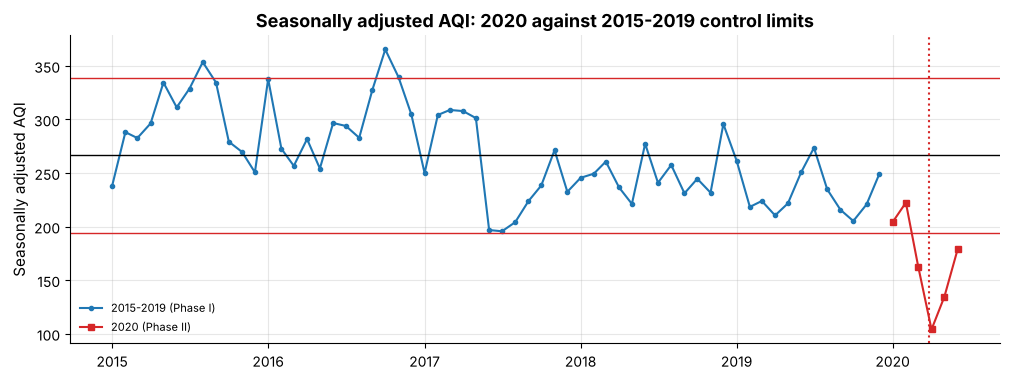

,mean_AQI,n,poor_days,adjusted,z vs Phase I,signal
Date,,,,,,
2020-01-01,308.45,31,29,204.26,-2.59,in control
2020-02-01,262.14,29,23,222.39,-1.84,in control
2020-03-01,135.84,31,3,162.44,-4.32,below LCL
2020-04-01,113.00,30,0,104.05,-6.75,below LCL
2020-05-01,148.65,31,4,134.53,-5.48,below LCL
2020-06-01,125.73,30,1,178.71,-3.65,below LCL


In [7]:
h20 = pd.read_csv(DATA_2020, parse_dates=["Date"]).set_index("Date")
m20 = h20.resample("MS").agg(mean_AQI=("AQI", "mean"), n=("AQI", "size"), poor_days=("Poor_Flag", "sum"))
m20 = m20[m20["n"] >= 28]                 # drop the 1-day July 2020 stub
clim_m = m.groupby(m.index.month)["mean_AQI"].mean()
m20["adjusted"] = m20["mean_AQI"] - clim_m.loc[m20.index.month].values + m["mean_AQI"].mean()
cA, sA, _ = i_mr(xs)
m20["z vs Phase I"] = (m20["adjusted"] - cA) / sA
m20["signal"] = np.where(m20["adjusted"] < cA - 3 * sA, "below LCL", np.where(m20["adjusted"] > cA + 3 * sA, "above UCL", "in control"))
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(xs.index, xs, "-o", ms=3, color="C0", label="2015-2019 (Phase I)")
ax.plot(m20.index, m20["adjusted"], "-s", ms=5, color="C3", label="2020 (Phase II)")
for v, ls in ((cA, "-"), (cA + 3 * sA, "-"), (cA - 3 * sA, "-")):
    ax.axhline(v, color="k" if v == cA else "C3", lw=1)
ax.axvline(pd.Timestamp("2020-03-25"), color="C3", ls=":")
ax.set(title="Seasonally adjusted AQI: 2020 against 2015-2019 control limits", ylabel="Seasonally adjusted AQI")
ax.legend(fontsize=8)
save_figure(fig, "06_phase2_2020"); plt.show()
m20.round(2)

**Phase II: 2020.** Against limits fixed from 2015-2019, January and February 2020 are in control (z = -2.6 and
-1.8; both are below the 5-year centre because of the improving trend). From **March 2020 every month is below the
lower control limit**, by 4.3 to 6.8 sigma, with April the most extreme (seasonally adjusted AQI 104, against an
LCL of 194). Only 0-4 days a month were Poor, against 23-29 in January-February. This is an unmistakable special
cause, the COVID-19 lockdown from 25 March 2020, the same structural break the forecast in notebook 05 detected.

## Save the chart data for the app

In [8]:
def to_rows(tab, chart):
    return pd.DataFrame({"month": tab.index.strftime("%Y-%m"), "value": tab["value"].values, "centre": tab["centre"].values,
                         "ucl": tab["ucl"].values, "lcl": tab["lcl"].values, "out_of_control": tab["out_of_control"].values,
                         "rule": tab["rule"].values, "chart": chart})

cc = pd.concat([to_rows(raw_tab, "Monthly mean AQI"), to_rows(adj_tab, "Seasonally adjusted AQI")], ignore_index=True)
cc.round(3).to_csv(CONTROL_CSV, index=False)
pc = pd.DataFrame({"month": m.index.strftime("%Y-%m"), "n_days": m["n"].values, "poor_days": m["poor_days"].values,
                   "p": m["p_poor"].values, "centre": pbar, "ucl": ucl_p.values, "lcl": lcl_p.values,
                   "ucl_laney": ucl_l.values, "lcl_laney": lcl_l.values, "out_of_control": p_out.astype(int).values,
                   "out_laney": l_out.astype(int).values})
pc.round(4).to_csv(PCHART_CSV, index=False)
print("saved", CONTROL_CSV.relative_to(ROOT), cc.shape, "and", PCHART_CSV.relative_to(ROOT), pc.shape)

saved outputs/control_chart.csv (120, 8) and outputs/p_chart.csv (60, 11)


## Summary: when is Delhi's air quality out of statistical control?

| Chart | What it shows | Verdict |
| --- | --- | --- |
| I-MR, raw monthly AQI | 14/60 signals, mostly the season itself | Not valid for a seasonal series |
| I-MR, seasonally adjusted | Rule-1 signals Aug 2015, Oct-Nov 2016; runs show a downward shift from mid-2017 | **Special causes: 2016 smog episode; sustained improvement** |
| X̄-S, month as subgroup | 45/60 outside | Rational subgrouping fails (between-month > within-month variation) |
| p-chart, share of Poor days | 36/60 outside; strong over-dispersion (χ² 1,015 on 59 df) | Use Laney p′: monsoon months systematically low |
| Phase II, 2020 | Mar-Jun 2020 4.3-6.8σ below LCL | **Special cause: COVID-19 lockdown** |

The general lesson for the viva: a control chart is only as good as its assumptions (a stable mean, independent
points, rational subgroups). Seasonality and autocorrelation must be removed first, and over-dispersion corrected,
or "out of control" just means "it is November".